In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, log10
from collections import deque
np.set_printoptions(precision=4, suppress=True)

Simulating sessions: 50
Simulating sessions: 100
Simulating sessions: 200
Simulating sessions: 300
Simulating sessions: 400
Simulating sessions: 500
Simulating sessions: 600
Simulating sessions: 800


,sessions,original_blocking_pct,original_useful_util_pct,redesign_burst_loss_pct,redesign_allocated_util_pct,redesign_messages_per_session_min,mean_access_delay_ms,collision_pct
0,50,0.00,6.49,0.00,7.04,18.39,5.74,1.39
1,100,23.00,10.00,0.03,13.74,18.06,32.49,5.30
2,200,61.50,10.00,74.20,20.18,25.94,472.86,9.17
3,300,74.33,10.00,89.89,20.01,34.98,489.35,3.69
4,400,80.75,10.00,93.93,19.64,40.05,497.92,2.18
5,500,84.60,10.00,95.53,19.78,42.78,497.73,1.61
6,600,87.17,10.00,96.49,20.04,44.69,495.33,1.34
7,800,90.38,10.00,97.55,19.95,47.04,498.32,0.89


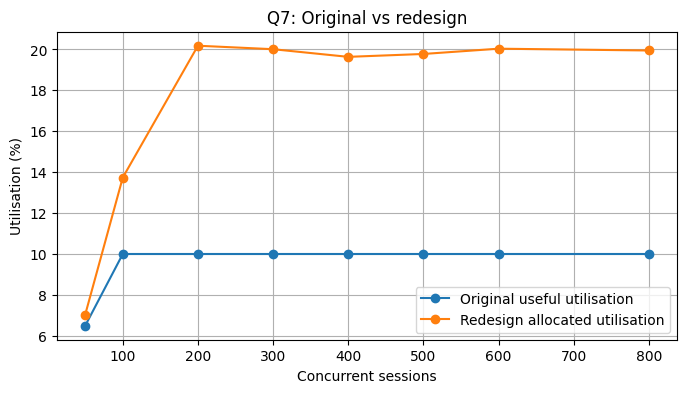

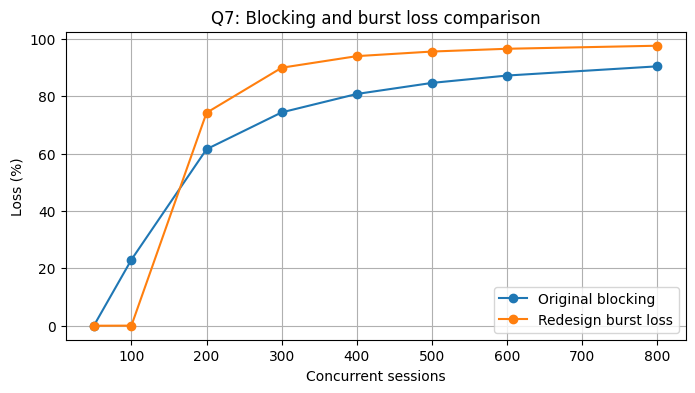

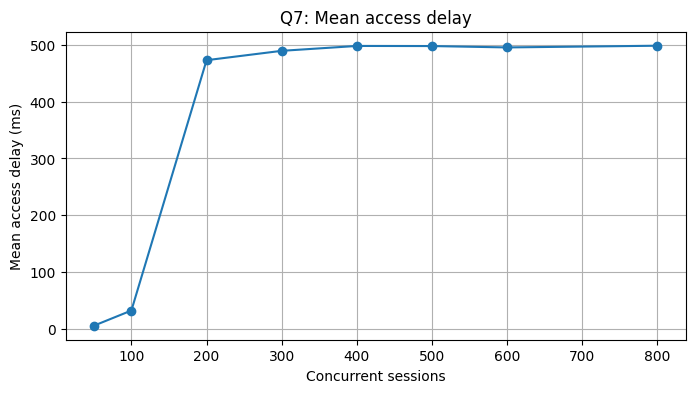

Q7 CSV file created successfully!


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def q7_simulate(M, seed, duration=1200, channels=77, dt=0.1):

    rng = np.random.default_rng(seed)
    steps = int(duration / dt)

    # Session states
    active = np.zeros(M, dtype=bool)
    pending = np.zeros(M, dtype=bool)

    # Initial OFF periods
    off_remaining = rng.exponential(9.0, M)
    burst_remaining = np.zeros(M)
    wait = np.zeros(M)

    served = blocked = expired = requests = 0
    grants = releases = collisions = 0
    channel_busy_steps = 0
    delay_samples = []

    # Original dedicated-channel allocation
    original_block = max(0, M - channels) / M
    original_useful = min(M, channels) * 0.1 / channels

    for step in range(steps):

        # 1. Finish active bursts
        burst_remaining[active] -= dt

        finished = active & (burst_remaining <= 0)

        releases += finished.sum()
        active[finished] = False

        # Finished sessions enter OFF state again
        off_remaining[finished] = rng.exponential(9.0, finished.sum())

        # 2. Generate new burst requests
        eligible = (~active) & (~pending)
        off_remaining[eligible] -= dt

        new_requests = eligible & (off_remaining <= 0)

        pending[new_requests] = True
        wait[new_requests] = 0

        requests += new_requests.sum()

        # 3. Load-adaptive contention
        contenders = np.flatnonzero(pending)

        q = min(1.0, 2.0 / max(len(contenders), 1))

        attempts = contenders[rng.random(len(contenders)) < q]

        if len(attempts) > 2:
            collisions += len(attempts) - 2

        rng.shuffle(attempts)

        # 4. Allocate at most two requests per time step
        for i in attempts[:2]:

            pending[i] = False

            if active.sum() < channels:

                active[i] = True
                burst_remaining[i] = rng.exponential(1.0)

                served += 1
                grants += 1
                delay_samples.append(wait[i])

            else:
                blocked += 1

        # 5. Update pending request waiting times
        wait[pending] += dt

        expired_now = pending & (wait > 1.0)

        expired += expired_now.sum()
        pending[expired_now] = False

        # 6. Channel utilisation
        channel_busy_steps += active.sum()

    # Final metrics
    useful = channel_busy_steps / (steps * channels)

    burst_loss = (
        (blocked + expired) /
        max(served + blocked + expired, 1)
    )

    messages = requests + grants + releases

    mean_delay = (
        np.mean(delay_samples) * 1000
        if delay_samples else 0
    )

    collision_pct = collisions / max(requests, 1) * 100

    return [
        M,
        original_block * 100,
        original_useful * 100,
        burst_loss * 100,
        useful * 100,
        messages / (M * duration / 60),
        mean_delay,
        collision_pct
    ]


# Run simulations
q7_rows = []

for M in (50, 100, 200, 300, 400, 500, 600, 800):
    print("Simulating sessions:", M)
    q7_rows.append(q7_simulate(M, 6000 + M))

# Create result table
q7 = pd.DataFrame(
    q7_rows,
    columns=[
        "sessions",
        "original_blocking_pct",
        "original_useful_util_pct",
        "redesign_burst_loss_pct",
        "redesign_allocated_util_pct",
        "redesign_messages_per_session_min",
        "mean_access_delay_ms",
        "collision_pct"
    ]
)

display(q7.round(2))

# Save results
q7.to_csv("q7_original_vs_redesign.csv", index=False)


# Visualisation 1: Utilisation comparison
plt.figure(figsize=(8, 4))

plt.plot(
    q7["sessions"],
    q7["original_useful_util_pct"],
    "o-",
    label="Original useful utilisation"
)

plt.plot(
    q7["sessions"],
    q7["redesign_allocated_util_pct"],
    "o-",
    label="Redesign allocated utilisation"
)

plt.xlabel("Concurrent sessions")
plt.ylabel("Utilisation (%)")
plt.title("Q7: Original vs redesign")
plt.grid(True)
plt.legend()
plt.show()


# Visualisation 2: Blocking and burst loss
plt.figure(figsize=(8, 4))

plt.plot(
    q7["sessions"],
    q7["original_blocking_pct"],
    "o-",
    label="Original blocking"
)

plt.plot(
    q7["sessions"],
    q7["redesign_burst_loss_pct"],
    "o-",
    label="Redesign burst loss"
)

plt.xlabel("Concurrent sessions")
plt.ylabel("Loss (%)")
plt.title("Q7: Blocking and burst loss comparison")
plt.grid(True)
plt.legend()
plt.show()


# Visualisation 3: Mean access delay
plt.figure(figsize=(8, 4))

plt.plot(
    q7["sessions"],
    q7["mean_access_delay_ms"],
    "o-"
)

plt.xlabel("Concurrent sessions")
plt.ylabel("Mean access delay (ms)")
plt.title("Q7: Mean access delay")
plt.grid(True)
plt.show()


print("Q7 CSV file created successfully!")